## Setup

In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

import compute_master_npz as cm

In [2]:
master_path = 'Data/npz/master.npz'        # WT (main + sup) + pert2
wnt_path    = 'Data/npz/wnt_master.npz'    # wnt_pert, complexity-only

# Wnt plate: well -> condition (the mapping compute_master_npz used), display order, references
WNT_CONDITIONS = json.load(open('Data/wnt_pert/config.json'))['condition_by_token']['map']
WNT_ORDER      = ['control', 'IWP2_24hr', 'IWP2_60hr', 'IWP2_60hr_HiWnt']
WNT_REF, WT_REF = 'control (d3.5)', 'WT day 3.5'   # plate control; time-matched WT
# one colour per plate condition (categorical slots 1–4, validated with the dataviz palette checker;
# yellow/aqua are < 3:1 on white, so every row also carries a text label)
WNT_COLOUR = dict(zip(WNT_ORDER, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))

L_CROSS_CAP = cm.COMPLEXITY_LMAX - 1       # l_cross saturates here (error never drops below threshold)

In [3]:
# --- one row per organoid: dataset / time / condition / l_cross / sphericity ---------------
def load_rows(path):
    m = np.load(path, allow_pickle=True)
    df = pd.DataFrame({
        'id':        m['ids'].astype(str),
        'dataset':   m['datasets'].astype(str),
        'time':      m['times'].astype(str),
        'condition': m['conditions'].astype(str),
        'area':      m['areas'],
        # recompute from the stored per-degree errors so both files use the same threshold
        'l_cross':   cm.compute_l_cross(m['complexity_errors'], cm.L_CROSS_THRESHOLD),
        # area-normalised RMSE of the SH reconstruction with degrees 0..8 (the last column);
        # unlike l_cross it does not saturate, so it still ranks the most complex organoids
        'err8':      m['complexity_errors'][:, cm.COMPLEXITY_LMAX - 1],
        # same with degrees 0..2 only: deviation from the coarse (roughly ellipsoidal) body
        'err2':      m['complexity_errors'][:, 2],
    })
    return df

df = pd.concat([load_rows(master_path), load_rows(wnt_path)], ignore_index=True)

# sphericity from each dataset's classical mesh features (keyed by the id minus the dataset prefix)
sph = {}
for d in df['dataset'].unique():
    mf = pd.read_csv(f'Data/{d}/feature_tables/mesh_features.csv')
    sph.update({f'{d}_{u}': s for u, s in zip(mf['label_uid'], mf['sphericity'])})
df['sphericity'] = df['id'].map(sph)
assert df['sphericity'].notna().all(), 'organoid missing from its mesh_features.csv'

# family + group label: WT per timepoint, pert2 per drug, wnt
df['family'] = np.select([df['dataset'] == 'wnt_pert', df['dataset'] == 'pert2'], ['wnt', 'pert2'], 'WT')
df['group'] = np.where(df['family'] == 'WT', 'WT day ' + df['time'].str.replace('p', '.'),
                       df['condition'] + ' (d' + df['time'].str.replace('p', '.') + ')')
print(df.groupby(['family', 'group']).size().to_string())

family  group                 
WT      WT day 1.5                100
        WT day 2                  100
        WT day 2.5                 99
        WT day 3                  100
        WT day 3.5                200
        WT day 4                  343
        WT day 4.5                425
        WT day 4.5-more           502
pert2   abs-Iwp2 (d4.5)           138
        sec-DaptHi (d4.5)         102
        stem-ChirVpaD1 (d4.5)     212
        ta-Yapa (d4.5)             38
wnt     IWP2_24hr (d3.5)          231
        IWP2_60hr (d3.5)          246
        IWP2_60hr_HiWnt (d3.5)    152
        control (d3.5)            242


In [4]:
# --- group order: WT by developmental time, then pert2 drugs, then the Wnt conditions
def _day(t):
    return float(t.split('-')[0].replace('p', '.')) + (0.01 if '-' in t else 0)

order = (sorted(df.loc[df.family == 'WT', 'group'].unique(),
                key=lambda g: _day(df.loc[df.group == g, 'time'].iloc[0]))
         + sorted(df.loc[df.family == 'pert2', 'group'].unique())
         + [g for g in (f'{c} (d3.5)' for c in WNT_ORDER) if g in set(df['group'])])

## Complexity (`l_cross`)

Per-group summary (`pct_at_cap` = share of organoids whose error never drops below the threshold by
degree 8), each Wnt condition against the plate control and WT day 3.5 (two-sided Mann–Whitney U;
`P(> ref)` = probability that a random organoid of the condition is more complex than a random
reference organoid), then the distributions for every group and for the Wnt plate alone.

In [5]:
# --- l_cross per group
summary = (df.groupby('group')['l_cross']
             .agg(n='size', median='median',
                  q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75),
                  pct_at_cap=lambda x: 100 * (x >= L_CROSS_CAP - 1e-9).mean())
             .reindex(order).round(2))
summary

,n,median,q25,q75,pct_at_cap
group,,,,,
WT day 1.5,100,2.01,1.87,2.40,0.00
WT day 2,100,2.31,1.99,2.55,0.00
WT day 2.5,99,2.35,2.01,2.67,0.00
WT day 3,100,2.52,2.10,2.90,0.00
WT day 3.5,200,2.89,2.60,3.42,0.00
WT day 4,343,3.08,2.71,3.83,0.00
WT day 4.5,425,3.40,2.70,4.66,5.88
WT day 4.5-more,502,3.21,2.69,4.58,4.58
abs-Iwp2 (d4.5),138,2.61,2.20,2.84,0.00


In [6]:
# --- each Wnt condition vs the plate control and vs WT day 3.5 (Mann-Whitney U)
# P(> ref) = probability a random organoid of the condition exceeds a random reference organoid
def compare(data, col):
    rows = []
    for g in [g for g in order if data.loc[data.group == g, 'family'].iloc[0] == 'wnt']:
        x = data.loc[data.group == g, col]
        row = {'group': g, 'n': len(x), 'median': x.median()}
        for ref, tag in ((WNT_REF, 'control'), (WT_REF, 'WT d3.5')):
            y = data.loc[data.group == ref, col]
            if ref == g:
                row.update({f'Δ median vs {tag}': np.nan, f'P(> {tag})': np.nan, f'p vs {tag}': ''})
                continue
            u, p = mannwhitneyu(x, y, alternative='two-sided')
            row.update({f'Δ median vs {tag}': x.median() - y.median(),
                        f'P(> {tag})': u / (len(x) * len(y)), f'p vs {tag}': f'{p:.1e}'})
        rows.append(row)
    return pd.DataFrame(rows).set_index('group')

compare(df, 'l_cross').round(3)

,n,median,Δ median vs control,P(> control),p vs control,Δ median vs WT d3.5,P(> WT d3.5),p vs WT d3.5
group,,,,,,,,
control (d3.5),242,3.667,NaN,NaN,,0.777,0.759,5.8e-21
IWP2_24hr (d3.5),231,2.824,-0.843,0.192,4.2e-31,-0.066,0.451,7.8e-02
IWP2_60hr (d3.5),246,2.658,-1.009,0.136,6.4e-44,-0.231,0.372,3.1e-06
IWP2_60hr_HiWnt (d3.5),152,2.858,-0.809,0.231,2.1e-19,-0.032,0.487,6.9e-01


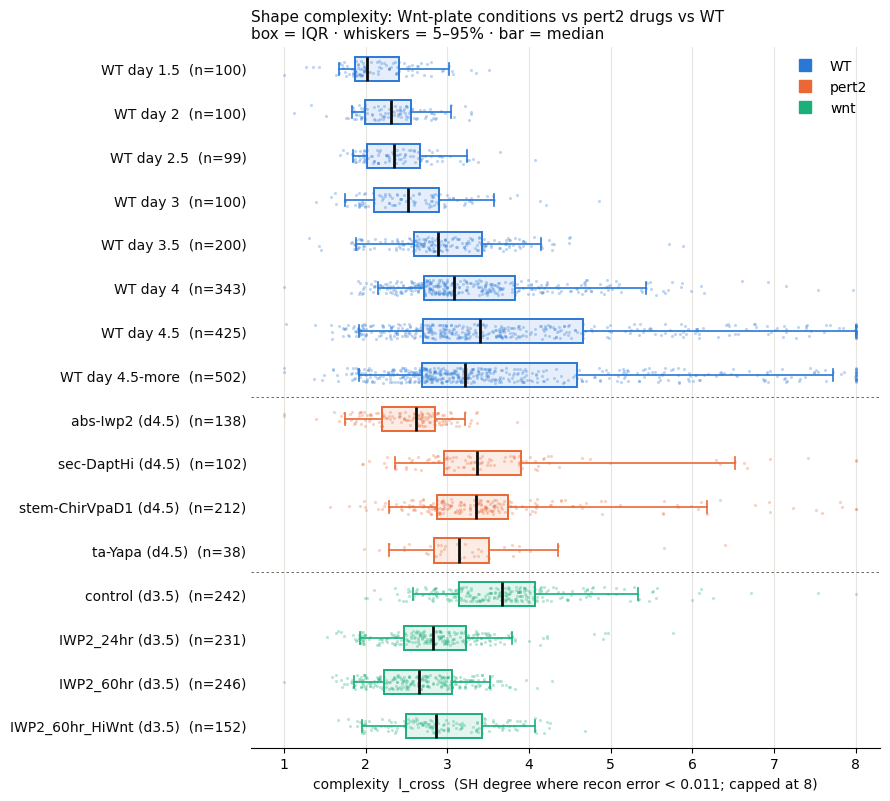

In [7]:
# --- l_cross for every group, coloured by dataset -> Figures/wnt_complexity_comparison.png
FAMILY_COLOUR = {'WT': '#2a78d6', 'pert2': '#eb6834', 'wnt': '#1baf7a'}
INK, MUTED = '#0b0b0b', '#52514e'
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.4))
for i, g in enumerate(order):
    sub = df[df.group == g]
    col = FAMILY_COLOUR[sub['family'].iloc[0]]
    ax.scatter(sub['l_cross'], i + rng.uniform(-0.17, 0.17, len(sub)),
               s=5, color=col, alpha=0.3, linewidths=0, zorder=2)
    ax.boxplot(sub['l_cross'], positions=[i], vert=False, widths=0.55, whis=(5, 95),
               showfliers=False, patch_artist=True, zorder=3,
               boxprops=dict(facecolor=(*plt.matplotlib.colors.to_rgb(col), 0.12), edgecolor=col, lw=1.4),
               whiskerprops=dict(color=col, lw=1.2), capprops=dict(color=col, lw=1.2),
               medianprops=dict(color=INK, lw=2))
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f'{g}  (n={int(summary.loc[g, "n"])})' for g in order], color=INK)
ax.invert_yaxis()
# thin separators between the WT / pert2 / wnt blocks
fam = [df.loc[df.group == g, 'family'].iloc[0] for g in order]
for i in range(1, len(order)):
    if fam[i] != fam[i - 1]:
        ax.axhline(i - 0.5, color=MUTED, lw=0.6, ls=(0, (3, 3)))
ax.set_xlabel('complexity  l_cross  (SH degree where recon error < '
              f'{cm.L_CROSS_THRESHOLD}; capped at {L_CROSS_CAP})', color=INK)
ax.set_xlim(0.6, L_CROSS_CAP + 0.3)
ax.grid(axis='x', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0)
handles = [plt.Line2D([], [], marker='s', ls='', ms=9, color=c, label=f) for f, c in FAMILY_COLOUR.items()]
ax.legend(handles=handles, loc='upper right', frameon=False, title=None)
ax.set_title('Shape complexity: Wnt-plate conditions vs pert2 drugs vs WT\n'
             'box = IQR · whiskers = 5–95% · bar = median', color=INK, fontsize=11, loc='left')
plt.tight_layout()
fig.savefig('Figures/wnt_complexity_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

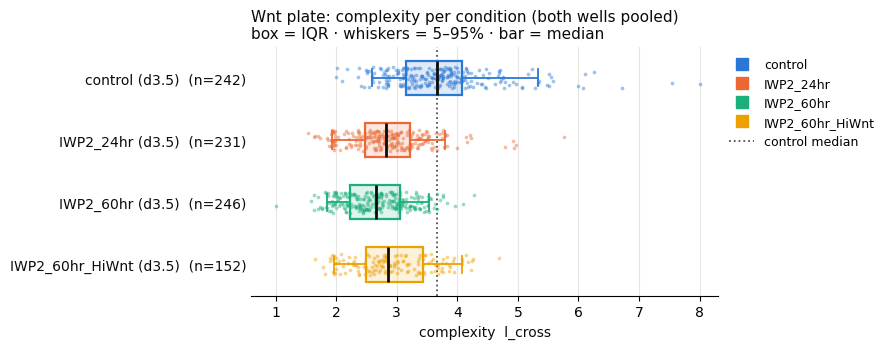

In [8]:
# --- Wnt plate only: l_cross per condition, wells pooled -> Figures/wnt_plate_complexity_by_condition.png
PLATE_GROUPS = [f'{c} (d3.5)' for c in WNT_ORDER]

def plate_panel(ax, data, var, points=True, names=True):
    # one row per condition (wells pooled), one colour per condition; dotted line = control median
    for i, c_name in enumerate(WNT_ORDER):
        sub = data[data.group == f'{c_name} (d3.5)']
        c = WNT_COLOUR[c_name]
        if points:
            ax.scatter(sub[var], i + rng.uniform(-0.17, 0.17, len(sub)), s=7, color=c,
                       alpha=0.45, linewidths=0, zorder=2)
        ax.boxplot(sub[var], positions=[i], vert=False, widths=0.55, whis=(5, 95), showfliers=False,
                   patch_artist=True, zorder=3,
                   boxprops=dict(facecolor=(*plt.matplotlib.colors.to_rgb(c), 0.15), edgecolor=c, lw=1.6),
                   whiskerprops=dict(color=c, lw=1.3), capprops=dict(color=c, lw=1.3),
                   medianprops=dict(color=INK, lw=2))
    ax.axvline(data.loc[data.group == WNT_REF, var].median(), color=MUTED, lw=1.3, ls=':',
               label='control median', zorder=1)
    ax.set_yticks(range(len(PLATE_GROUPS)))
    ax.set_yticklabels([(f'{g}  ' if names else '') + f'(n={(data.group == g).sum()})'
                        for g in PLATE_GROUPS], color=INK)
    ax.set_ylim(len(PLATE_GROUPS) - 0.5, -0.5)
    ax.grid(axis='x', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
    for s in ('top', 'right', 'left'):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis='y', length=0)

def plate_legend(ax, **kw):
    handles = [plt.Line2D([], [], marker='s', ls='', ms=9, color=WNT_COLOUR[c], label=c) for c in WNT_ORDER]
    handles.append(plt.Line2D([], [], color=MUTED, lw=1.3, ls=':', label='control median'))
    ax.legend(handles=handles, frameon=False, fontsize=9, **kw)

fig, ax = plt.subplots(figsize=(9, 0.55 * len(PLATE_GROUPS) + 1.4))
plate_panel(ax, df, 'l_cross')
ax.set_xlabel('complexity  l_cross', color=INK); ax.set_xlim(0.6, L_CROSS_CAP + 0.3)
plate_legend(ax, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.set_title('Wnt plate: complexity per condition (both wells pooled)\n'
             'box = IQR · whiskers = 5–95% · bar = median', color=INK, fontsize=11, loc='left')
plt.tight_layout()
fig.savefig('Figures/wnt_plate_complexity_by_condition.png', dpi=200, bbox_inches='tight')
plt.show()

## Reconstruction error at a fixed degree

`err{k}` = area-normalised RMSE between the mesh and its SH reconstruction from degrees 0..*k*
(column *k* of `complexity_errors`); `err{k}` below the threshold ⇔ `l_cross` ≤ *k*.

- **degree 8** — the error left after a fine reconstruction. It keeps ranking the most complex
  organoids where `l_cross` saturates, but for near-spheres it is mostly mesh noise, whose level
  differs by dataset (≈ 0.0005–0.0008 for WT and Wnt, ≈ 0.001 for pert2 and sup) — compare pert2
  with care.
- **degree 2** — the error left after only the coarse, roughly ellipsoidal body: buds, lobes and
  bends. Noise is a small part of it, so it compares fairly across datasets.

Each degree: per-group summary, Wnt conditions vs references, then the figure
(`Figures/wnt_err8_comparison.png`, `Figures/wnt_err2_comparison.png`).

In [9]:
# --- helpers: per-group summary and figure for err{k}
def err_summary(col):
    s = (df.groupby('group')[col]
           .agg(n='size', median='median',
                q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75),
                pct_above_threshold=lambda x: 100 * (x > cm.L_CROSS_THRESHOLD).mean())
           .reindex(order))
    return s


def plot_err(col, degree, out):
    s = err_summary(col)
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.4))
    for i, g in enumerate(order):
        sub = df[df.group == g]
        c = FAMILY_COLOUR[sub['family'].iloc[0]]
        ax.scatter(sub[col], i + rng.uniform(-0.17, 0.17, len(sub)),
                   s=5, color=c, alpha=0.3, linewidths=0, zorder=2)
        ax.boxplot(sub[col], positions=[i], vert=False, widths=0.55, whis=(5, 95),
                   showfliers=False, patch_artist=True, zorder=3,
                   boxprops=dict(facecolor=(*plt.matplotlib.colors.to_rgb(c), 0.12), edgecolor=c, lw=1.4),
                   whiskerprops=dict(color=c, lw=1.2), capprops=dict(color=c, lw=1.2),
                   medianprops=dict(color=INK, lw=2))
    ax.set_xscale('log')
    lo, hi = df[col].min(), df[col].max()
    ticks = [t for t in (1e-4, 2e-4, 3e-4, 5e-4, 1e-3, 2e-3, 3e-3, 5e-3, 1e-2, 2e-2, 3e-2, 5e-2, 1e-1)
             if lo / 1.5 <= t <= hi * 1.5]
    ax.set_xticks(ticks); ax.set_xticklabels([f'{t:g}' for t in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.axvline(cm.L_CROSS_THRESHOLD, color=MUTED, lw=1, ls='--')
    ax.text(cm.L_CROSS_THRESHOLD, -0.75, f' l_cross threshold {cm.L_CROSS_THRESHOLD}\n'
            f' (left: l_cross ≤ {degree} · right: > {degree})', color=MUTED, fontsize=9, va='center')
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f'{g}  (n={int(s.loc[g, "n"])})' for g in order], color=INK)
    ax.invert_yaxis(); ax.set_ylim(len(order) - 0.5, -1.0)
    fam = [df.loc[df.group == g, 'family'].iloc[0] for g in order]
    for i in range(1, len(order)):
        if fam[i] != fam[i - 1]:
            ax.axhline(i - 0.5, color=MUTED, lw=0.6, ls=(0, (3, 3)))
    ax.set_xlabel(f'reconstruction error at degree {degree}  '
                  f'(area-normalised RMSE, SH degrees 0..{degree}; log scale)', color=INK)
    ax.grid(axis='x', which='both', color='#e6e5e0', lw=0.6); ax.set_axisbelow(True)
    for sp in ('top', 'right', 'left'):
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    handles = [plt.Line2D([], [], marker='s', ls='', ms=9, color=c, label=f) for f, c in FAMILY_COLOUR.items()]
    ax.legend(handles=handles, loc='lower left', bbox_to_anchor=(1.0, 0.0), frameon=False)
    ax.set_title(f'Reconstruction error at degree {degree}: Wnt-plate conditions vs pert2 drugs vs WT\n'
                 'box = IQR · whiskers = 5–95% · bar = median', color=INK, fontsize=11, loc='left')
    plt.tight_layout()
    fig.savefig(out, dpi=200, bbox_inches='tight')
    plt.show()


ERR_FMT = {'median': '{:.5f}', 'q25': '{:.5f}', 'q75': '{:.5f}', 'pct_above_threshold': '{:.1f}'}

In [10]:
display(err_summary('err8').style.format(ERR_FMT))
compare(df, 'err8').round(5)

,n,median,q25,q75,pct_above_threshold
group,,,,,
WT day 1.5,100,0.00289,0.00275,0.00305,0.0
WT day 2,100,0.00289,0.00272,0.00311,0.0
WT day 2.5,99,0.00298,0.00274,0.00308,0.0
WT day 3,100,0.00307,0.00281,0.00322,0.0
WT day 3.5,200,0.00323,0.00299,0.00373,0.0
WT day 4,343,0.00351,0.00316,0.00438,0.0
WT day 4.5,425,0.00389,0.00319,0.00592,5.9
WT day 4.5-more,502,0.00359,0.00313,0.00560,4.6
abs-Iwp2 (d4.5),138,0.00326,0.00305,0.00355,0.0


,n,median,Δ median vs control,P(> control),p vs control,Δ median vs WT d3.5,P(> WT d3.5),p vs WT d3.5
group,,,,,,,,
control (d3.5),242,0.00408,NaN,NaN,,0.00085,0.77899,5.4e-24
IWP2_24hr (d3.5),231,0.00343,-0.00065,0.25412,2.3e-20,0.00020,0.58429,2.5e-03
IWP2_60hr (d3.5),246,0.00324,-0.00085,0.17276,6.8e-36,0.00001,0.47030,2.8e-01
IWP2_60hr_HiWnt (d3.5),152,0.00348,-0.00060,0.28385,5.0e-13,0.00025,0.63211,2.2e-05


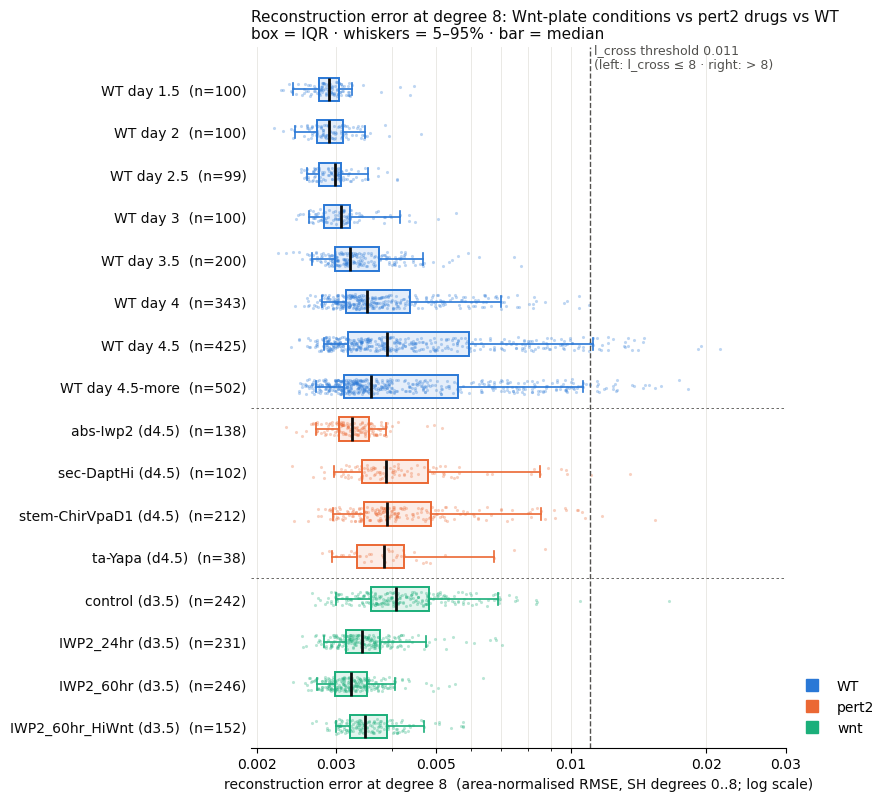

In [11]:
plot_err('err8', 8, 'Figures/wnt_err8_comparison.png')

In [12]:
display(err_summary('err2').style.format(ERR_FMT))
compare(df, 'err2').round(5)

,n,median,q25,q75,pct_above_threshold
group,,,,,
WT day 1.5,100,0.01104,0.01019,0.01220,51.0
WT day 2,100,0.01177,0.01093,0.01289,73.0
WT day 2.5,99,0.01183,0.01102,0.01281,75.8
WT day 3,100,0.01243,0.01121,0.01463,77.0
WT day 3.5,200,0.01436,0.01250,0.01713,89.5
WT day 4,343,0.01549,0.01326,0.02085,96.8
WT day 4.5,425,0.01690,0.01298,0.02588,90.4
WT day 4.5-more,502,0.01607,0.01321,0.02513,93.0
abs-Iwp2 (d4.5),138,0.01260,0.01139,0.01341,83.3


,n,median,Δ median vs control,P(> control),p vs control,Δ median vs WT d3.5,P(> WT d3.5),p vs WT d3.5
group,,,,,,,,
control (d3.5),242,0.01846,NaN,NaN,,0.00409,0.76310,1.6e-21
IWP2_24hr (d3.5),231,0.01345,-0.00500,0.16062,2.5e-37,-0.00091,0.41301,1.8e-03
IWP2_60hr (d3.5),246,0.01272,-0.00574,0.09195,7.7e-55,-0.00165,0.32116,8.1e-11
IWP2_60hr_HiWnt (d3.5),152,0.01348,-0.00497,0.16646,7.2e-29,-0.00088,0.41796,8.4e-03


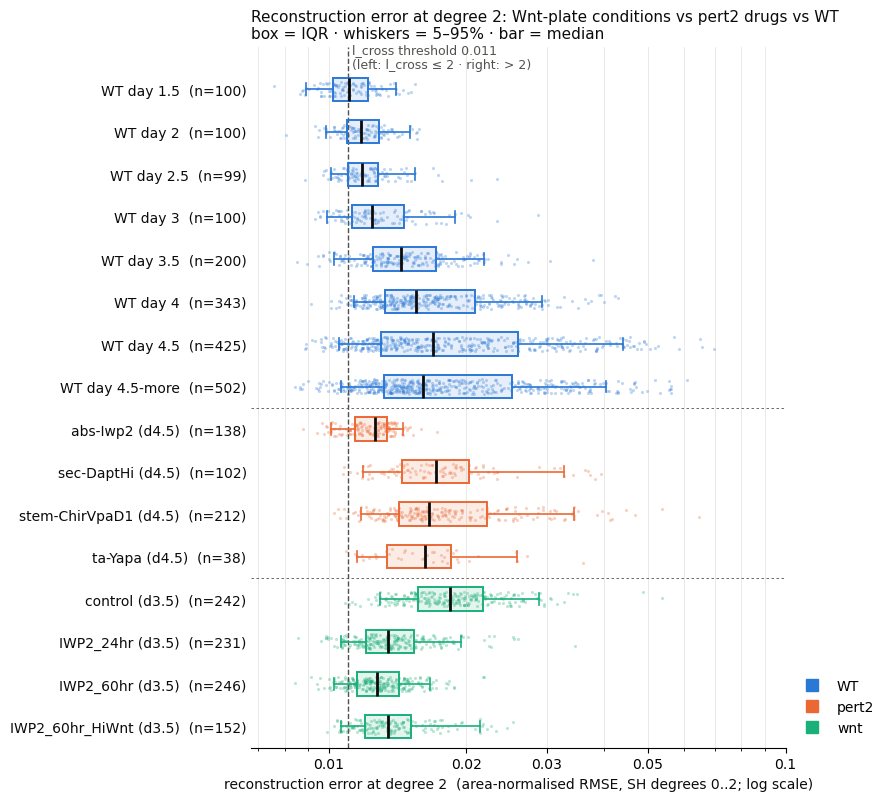

In [13]:
plot_err('err2', 2, 'Figures/wnt_err2_comparison.png')

## Sphericity

`sphericity` = surface area / area of the equal-volume sphere (1 = perfect sphere; higher = less
round), from each dataset's `feature_tables/mesh_features.csv`, for the same organoids as above.
Surface roughness at these meshes' dihedral angles (~2–3°) changes the area by only ~0.1%, so it does
not bias the comparison.

In [14]:
# --- sphericity per group
sph_df = df
sph_summary = (sph_df.groupby('group')['sphericity']
                 .agg(n='size', median='median',
                      q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75),
                      pct_above_1_3=lambda x: 100 * (x > 1.3).mean())
                 .reindex(order).round(3))
sph_summary

,n,median,q25,q75,pct_above_1_3
group,,,,,
WT day 1.5,100,1.009,1.006,1.013,0.000
WT day 2,100,1.010,1.009,1.015,0.000
WT day 2.5,99,1.012,1.008,1.018,0.000
WT day 3,100,1.015,1.009,1.025,0.000
WT day 3.5,200,1.030,1.013,1.048,0.000
WT day 4,343,1.040,1.019,1.078,0.000
WT day 4.5,425,1.047,1.014,1.128,4.471
WT day 4.5-more,502,1.042,1.020,1.120,2.789
abs-Iwp2 (d4.5),138,1.011,1.010,1.016,0.000


In [15]:
# --- each Wnt condition vs the plate control and vs WT day 3.5 (Mann-Whitney U)
compare(sph_df, 'sphericity').round(3)

,n,median,Δ median vs control,P(> control),p vs control,Δ median vs WT d3.5,P(> WT d3.5),p vs WT d3.5
group,,,,,,,,
control (d3.5),242,1.060,NaN,NaN,,0.029,0.766,5.3e-22
IWP2_24hr (d3.5),231,1.018,-0.041,0.140,1.0e-41,-0.012,0.404,5.5e-04
IWP2_60hr (d3.5),246,1.013,-0.047,0.059,9.9e-64,-0.017,0.289,1.8e-14
IWP2_60hr_HiWnt (d3.5),152,1.016,-0.044,0.126,6.8e-36,-0.015,0.382,1.6e-04


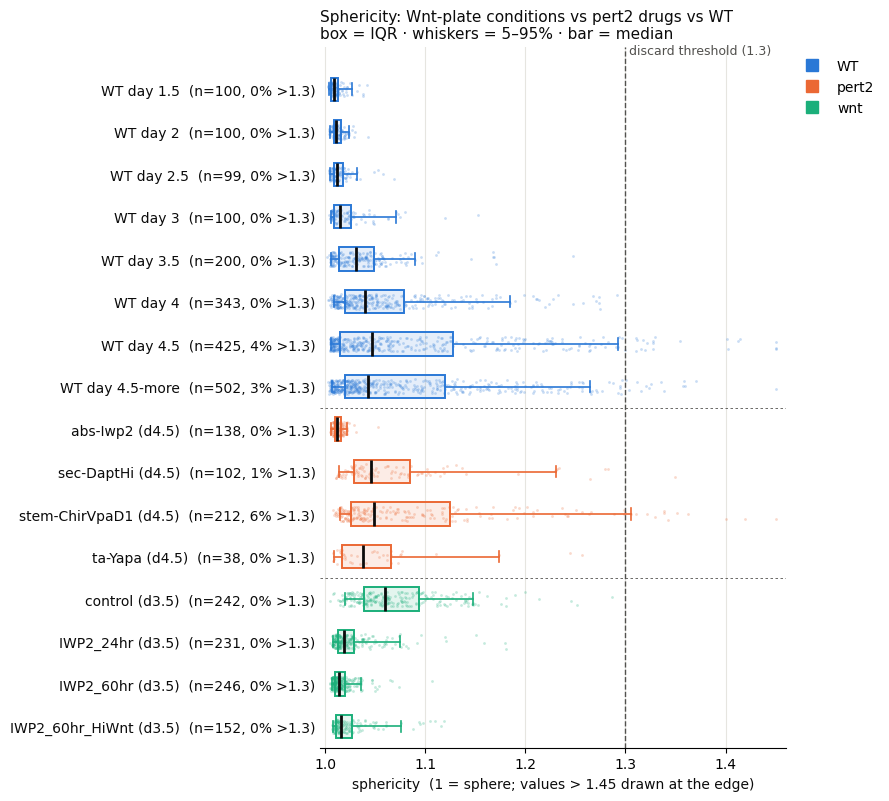

In [16]:
# --- sphericity for every group -> Figures/wnt_sphericity_comparison.png
SPH_MAX_SHOWN = 1.45
fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.4))
for i, g in enumerate(order):
    sub = sph_df[sph_df.group == g]
    col = FAMILY_COLOUR[sub['family'].iloc[0]]
    x = sub['sphericity'].clip(upper=SPH_MAX_SHOWN)          # tail piled at the right edge
    ax.scatter(x, i + rng.uniform(-0.17, 0.17, len(x)), s=4, color=col,
               alpha=0.25 if len(x) < 1000 else 0.08, linewidths=0, zorder=2)
    ax.boxplot(sub['sphericity'], positions=[i], vert=False, widths=0.55, whis=(5, 95),
               showfliers=False, patch_artist=True, zorder=3,
               boxprops=dict(facecolor=(*plt.matplotlib.colors.to_rgb(col), 0.12), edgecolor=col, lw=1.4),
               whiskerprops=dict(color=col, lw=1.2), capprops=dict(color=col, lw=1.2),
               medianprops=dict(color=INK, lw=2))
ax.axvline(1.3, color=MUTED, lw=1, ls='--')
ax.text(1.3, -0.75, ' discard threshold (1.3)', color=MUTED, fontsize=9, va='bottom')
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f'{g}  (n={int(sph_summary.loc[g, "n"])}, {sph_summary.loc[g, "pct_above_1_3"]:.0f}% >1.3)'
                    for g in order], color=INK)
ax.invert_yaxis(); ax.set_ylim(len(order) - 0.5, -1.0)
fam = [sph_df.loc[sph_df.group == g, 'family'].iloc[0] for g in order]
for i in range(1, len(order)):
    if fam[i] != fam[i - 1]:
        ax.axhline(i - 0.5, color=MUTED, lw=0.6, ls=(0, (3, 3)))
ax.set_xlim(0.995, SPH_MAX_SHOWN + 0.01)
ax.set_xlabel(f'sphericity  (1 = sphere; values > {SPH_MAX_SHOWN} drawn at the edge)', color=INK)
ax.grid(axis='x', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0)
handles = [plt.Line2D([], [], marker='s', ls='', ms=9, color=c, label=f) for f, c in FAMILY_COLOUR.items()]
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.set_title('Sphericity: Wnt-plate conditions vs pert2 drugs vs WT\n'
             'box = IQR · whiskers = 5–95% · bar = median', color=INK, fontsize=11, loc='left')
plt.tight_layout()
fig.savefig('Figures/wnt_sphericity_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

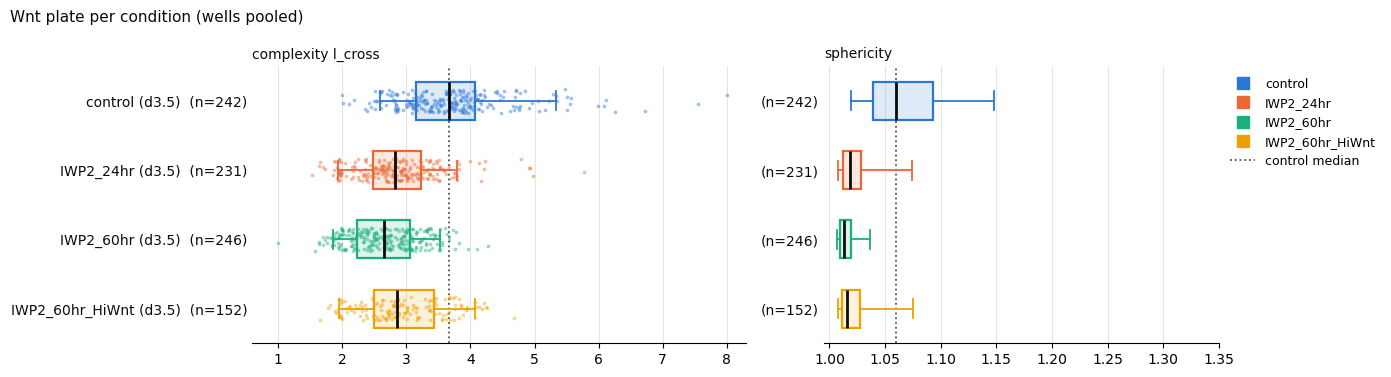

In [17]:
# --- Wnt plate only: complexity and sphericity side by side -> Figures/wnt_plate_by_condition.png
fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * len(PLATE_GROUPS) + 1.6),
                         gridspec_kw={'width_ratios': [1.25, 1]})
plate_panel(axes[0], df, 'l_cross')
plate_panel(axes[1], sph_df, 'sphericity', points=False, names=False)   # own n per panel
axes[0].set_xlim(0.6, L_CROSS_CAP + 0.3)
axes[0].set_title('complexity l_cross', color=INK, fontsize=10, loc='left')
axes[1].set_xlim(0.995, 1.35)
axes[1].set_title('sphericity', color=INK, fontsize=10, loc='left')
plate_legend(axes[1], loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.suptitle('Wnt plate per condition (wells pooled)', color=INK, fontsize=11,
             x=0.01, ha='left')
plt.tight_layout()
fig.savefig('Figures/wnt_plate_by_condition.png', dpi=200, bbox_inches='tight')
plt.show()

## Export

`output/wnt_complexity_recon_errors.csv` — one row per organoid in `wnt_master.npz`, with exactly the
columns of `complexity_analysis.ipynb`'s `output/complexity_recon_errors.csv`: `uid`, `dataset`,
`time`, `area`, `error_lmax0`–`error_lmax8`, `l_cross_thr0.0060`–`l_cross_thr0.0240`. The condition
and well are part of the `uid` (`wnt_pert_{condition}_day3p5_{well}_{label}`). `error_lmax{l}` uses
SH degrees 0..*l* (`error_lmax0` = the single degree-0 mode); `area` is in pipeline units
(× 100 = µm²), as in the other file.

In [18]:
wm = np.load(wnt_path, allow_pickle=True)
errors_w = wm['complexity_errors'].astype(float)
thresholds = np.round(np.arange(0.006, 0.0241, 0.002), 4)   # same sweep as complexity_analysis.ipynb

# same columns, in the same order, as complexity_analysis.ipynb's export
out = pd.DataFrame({'uid': wm['ids'].astype(str), 'dataset': wm['datasets'].astype(str),
                    'time': wm['times'].astype(str), 'area': wm['areas']})
for l in range(cm.COMPLEXITY_LMAX):
    out[f'error_lmax{l}'] = errors_w[:, l]
for t in thresholds:
    out[f'l_cross_thr{t:.4f}'] = cm.compute_l_cross(errors_w, t)
assert np.allclose(cm.compute_l_cross(errors_w), wm['l_cross_values'])

out_path = 'output/wnt_complexity_recon_errors.csv'
out.to_csv(out_path, index=False)
print(f'wrote {len(out)} rows x {len(out.columns)} cols -> {out_path}')
ref_cols = pd.read_csv('output/complexity_recon_errors.csv', nrows=0).columns.tolist()
assert out.columns.tolist() == ref_cols, 'columns differ from complexity_analysis export'

wrote 871 rows x 23 cols -> output/wnt_complexity_recon_errors.csv


In [19]:
print(out) 

                                   uid   dataset time        area  \
0    wnt_pert_IWP2_24hr_day3p5_E02_103  wnt_pert  3p5  256.662380   
1    wnt_pert_IWP2_24hr_day3p5_E02_104  wnt_pert  3p5  245.039414   
2    wnt_pert_IWP2_24hr_day3p5_E02_106  wnt_pert  3p5  259.708110   
3    wnt_pert_IWP2_24hr_day3p5_E02_108  wnt_pert  3p5  108.192905   
4    wnt_pert_IWP2_24hr_day3p5_E02_109  wnt_pert  3p5  253.575940   
..                                 ...       ...  ...         ...   
866      wnt_pert_control_day3p5_D03_8  wnt_pert  3p5  241.509428   
867     wnt_pert_control_day3p5_D03_84  wnt_pert  3p5  154.840183   
868     wnt_pert_control_day3p5_D03_88  wnt_pert  3p5  254.256670   
869     wnt_pert_control_day3p5_D03_92  wnt_pert  3p5  151.352890   
870     wnt_pert_control_day3p5_D03_93  wnt_pert  3p5  180.378827   

     error_lmax0  error_lmax1  error_lmax2  error_lmax3  error_lmax4  \
0       0.282023     0.026021     0.014068     0.011013     0.008259   
1       0.281695     0.0132